# 01 · Analyse exploratoire (Phase 1)
La logique est dans `src/eda.py` (reproductible : `python -m src.eda`, ~5 min). Ce notebook affiche les résultats.

**Hypothèses** : prix en devise locale (taux de change non validés) ; centre-ville = médiane des coordonnées ; langue des avis estimée sur un échantillon (~24 k avis, `langdetect`).

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'reports' / 'figures'
def fig(n): display(Image(FIG / f'eda_{n}.png'))

In [2]:
# Insights chiffrés (générés par src/eda.py)
display(Markdown((ROOT / 'reports' / 'eda_insights.md').read_text(encoding='utf-8')))

# Insights EDA (Phase 1)

Base : 485,128 annonces, 15 villes, une date de collecte par ville (sept. 2026). Tous les chiffres sont calculés par `src/eda.py`.
Prix en devise locale ; aucune conversion tant que les taux ne sont pas validés. Centre-ville = médiane des coordonnées (hypothèse).

1. 13 colonnes sont vides (100 %) dans toutes les villes : neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, bathrooms, calendar_updated, instant_bookable. À supprimer.
2. `price` manque pour 25.3 % des annonces (de 6.6 % à tokyo à 44.9 % à lyon) : 362,593 annonces exploitables pour la régression.
3. Biais de sélection : parmi les annonces SANS prix, 77 % ont availability_365 = 0, contre 5 % parmi celles avec prix (le prix n'existe que pour les annonces réservables).
4. Colonnes partiellement vides (>30 % en moyenne) : source (73 %), host_about (45 %), neighbourhood_group_cleansed (60 %), license (42 %).
5. Paris : asymétrie du prix = 56.9 (brut) contre 0.60 (log) : le log(prix) est quasi symétrique, d'où la cible log(price).
6. Médianes en devise locale (NON comparables sans conversion) : lyon 110 EUR, berlin 130 EUR, lisbon 140 EUR, madrid 151 EUR, toronto 161 CAD, london 175 GBP, new-york-city 182 USD, rome 188 EUR, barcelona 191 EUR, los-angeles 215 USD, paris 218 EUR, amsterdam 285 EUR, sydney 338 AUD, mexico-city 1,500 MXN, tokyo 20,322 JPY.
7. Prix relatif médian (1 = médiane de la ville) par room_type : Hotel room 1.54, Entire home/apt 1.16, Private room 0.54, Shared room 0.22 ; répartition : Entire home/apt 74 %, Private room 25 %, Hotel room 0 %, Shared room 0 %.
8. Outliers de prix : prix = 0 : 0 ; prix max global 3,465,263 (devise locale, tokyo). Rapport p99,9 / médiane le plus élevé : madrid (61x). Prix > 20x la médiane de sa ville : 935 annonces.
9. Prix < 0,1x la médiane de sa ville : 121 annonces (prix aberrants bas possibles : devis par mois ou erreurs).
10. Dispersion du prix relatif (p1 → p99) : médiane des villes 0.21 → 7.27.
11. Corrélations de Spearman avec log(price) : accommodates +0.47, beds +0.42, bedrooms +0.34, minimum_nights -0.24, reviews_per_month +0.17.
12. Paires redondantes (|Spearman| > 0,85) : number_of_reviews_ltm~reviews_per_month (0.85).
13. Variables les plus asymétriques (à log-transformer) : maximum_nights (81), price (57), minimum_nights (9), number_of_reviews_ltm (8), reviews_per_month (8).
14. property_type : 141 modalités, dont 131 rares (<1 %) couvrant 7.7 % des annonces → regroupement nécessaire.
15. Quartiers (neighbourhood_cleansed) : de 9 (lyon) à 264 (los-angeles) par ville ; 1294 couples ville-quartier → forte cardinalité, target encoding avec CV interne.
16. Paris : prix médian par arrondissement de 148 € (Ménilmontant) à 349 € (Élysée), soit un écart de x2.4.
17. Corrélation de Spearman distance au centre ↔ log(prix) : de -0.55 (rome) à +0.03 (los-angeles) ; la distance (centre = médiane des coordonnées, hypothèse) est négativement liée au prix dans 14 villes sur 15.
18. Superhosts : 30.0 % des annonces (de 16 % à amsterdam à 53 % à tokyo).
19. Hôtes professionnels : 38.2 % des annonces appartiennent à un hôte avec ≥ 5 annonces dans la ville (de 7 % à amsterdam à 74 % à tokyo) ; 18.6 % à un hôte avec ≥ 20 annonces.
20. Annonces par hôte : 485,128 annonces pour 253,996 hôtes distincts → un split par annonce ferait fuiter les hôtes ; split groupé par host_id confirmé.
21. Les hôtes multi-annonces (≥ 5) ont un prix relatif médian de 1.06 contre 0.96 pour les autres.
22. Ancienneté médiane de l'hôte : 5.0 ans (Superhost) contre 5.0 ans (non Superhost).
23. Avis : 18.6 % des annonces n'ont aucun avis ; note moyenne 4.73, médiane 4.84, 87 % des notes ≥ 4,5 : forte positivité, peu discriminante.
24. Note (81 % renseignée) : Superhost 4.86 contre 4.66 pour les non-Superhosts.
25. Langues des avis (échantillon de 23,994 avis, langdetect) : en 62 %, es 14 %, fr 10 %, de 4 %, it 2 %, pt 2 % ; 29 langues < 1 % (multilingue → modèles multilingues en phase 9).
26. Annonces fantômes : 23.0 % ont availability_365 = 0 ; 15.2 % cumulent indisponibilité ET 0 avis sur 12 mois (de 1 % à tokyo à 33 % à lyon).
27. `source` = « previous scrape » pour 27 % des annonces (non rafraîchies lors de la dernière collecte) ; parmi elles, 80 % n'ont pas de prix contre 5 % pour les autres.
28. FUITE (régression) : estimated_revenue_l365d = prix x occupation estimée : ratio = 1,00 pour 100 % des annonces avec occupation > 0 → à exclure ; price_quote_* est le prix lui-même (Spearman 1.00 avec `price`) → à exclure.
29. RISQUE DE FUITE (Superhost) : la seule note review_scores_rating donne un AUC de 0.63 et number_of_reviews_ltm de 0.77 pour prédire is_superhost ; ces variables sont à la fois critères d'attribution et conséquences du statut → à tester avec/sans en phase 7.
30. Colonnes connues seulement après coup / dérivées de la cible : estimated_revenue_l365d, estimated_occupancy_l365d, price_quote_*, price_rel_city_median (si recréé), availability_* et reviews_per_month (mesurent l'activité récente, pas les caractéristiques du logement).


## 1. Valeurs manquantes
Les colonnes 100 % vides sont à supprimer. Le prix manque surtout pour les annonces indisponibles ou non rafraîchies (biais de sélection).

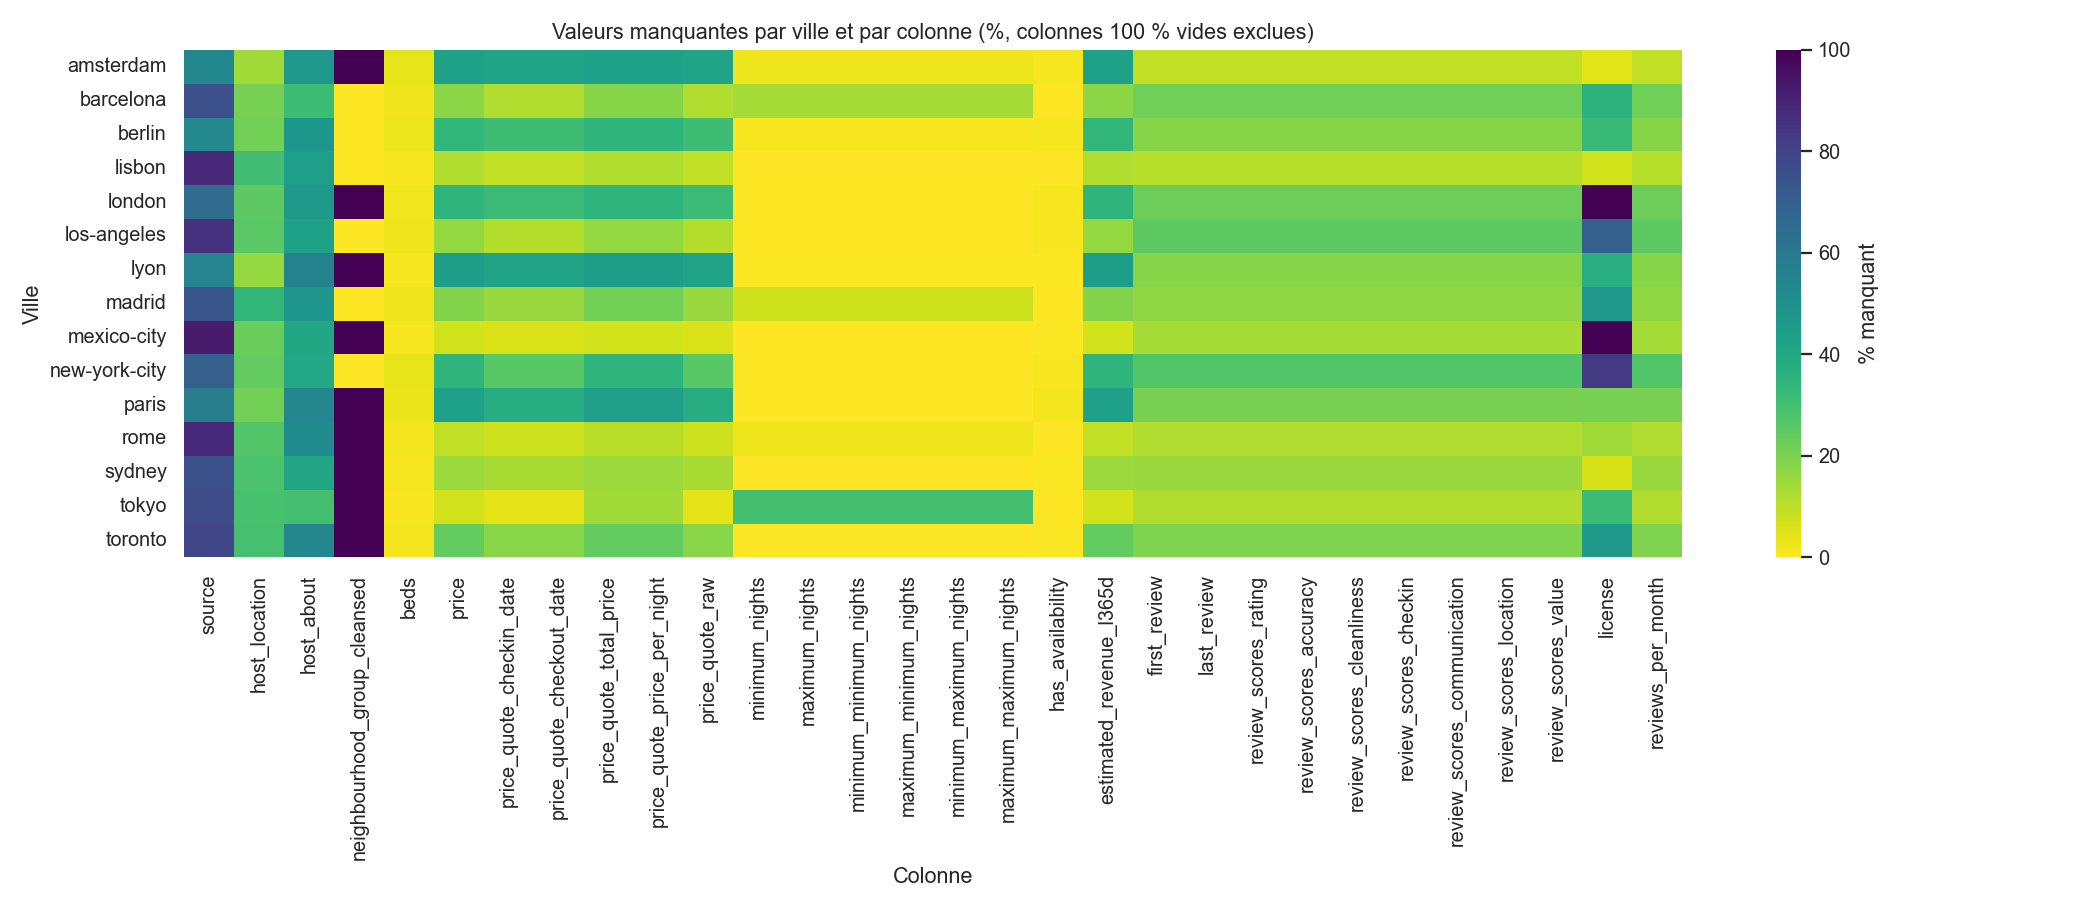

In [3]:
fig('01_missing_heatmap')

## 2. Prix
Distribution très asymétrique en brut, quasi symétrique en log. Les devises locales empêchent toute comparaison directe entre villes.

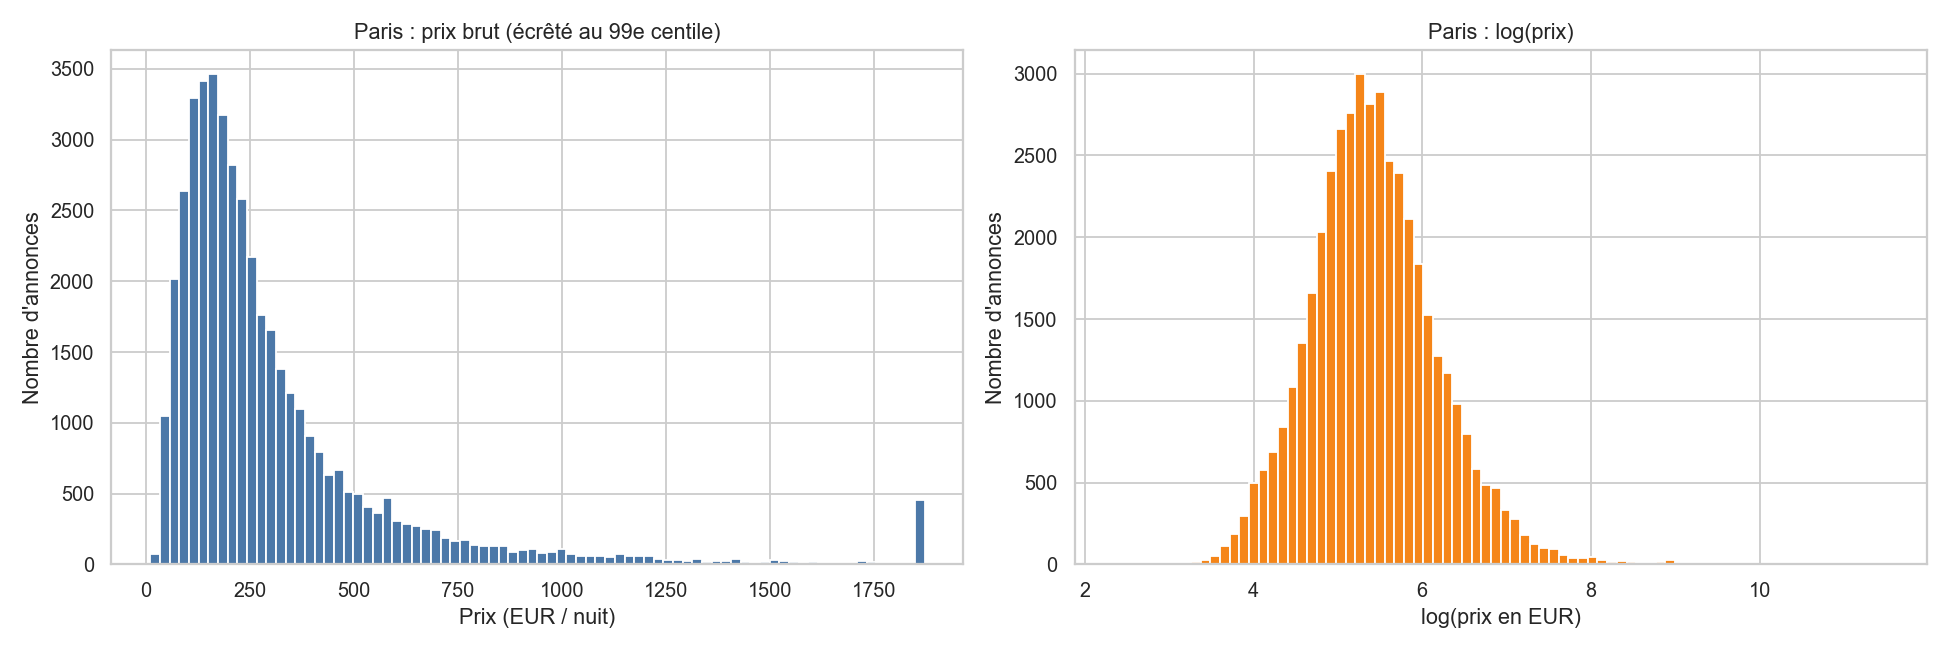

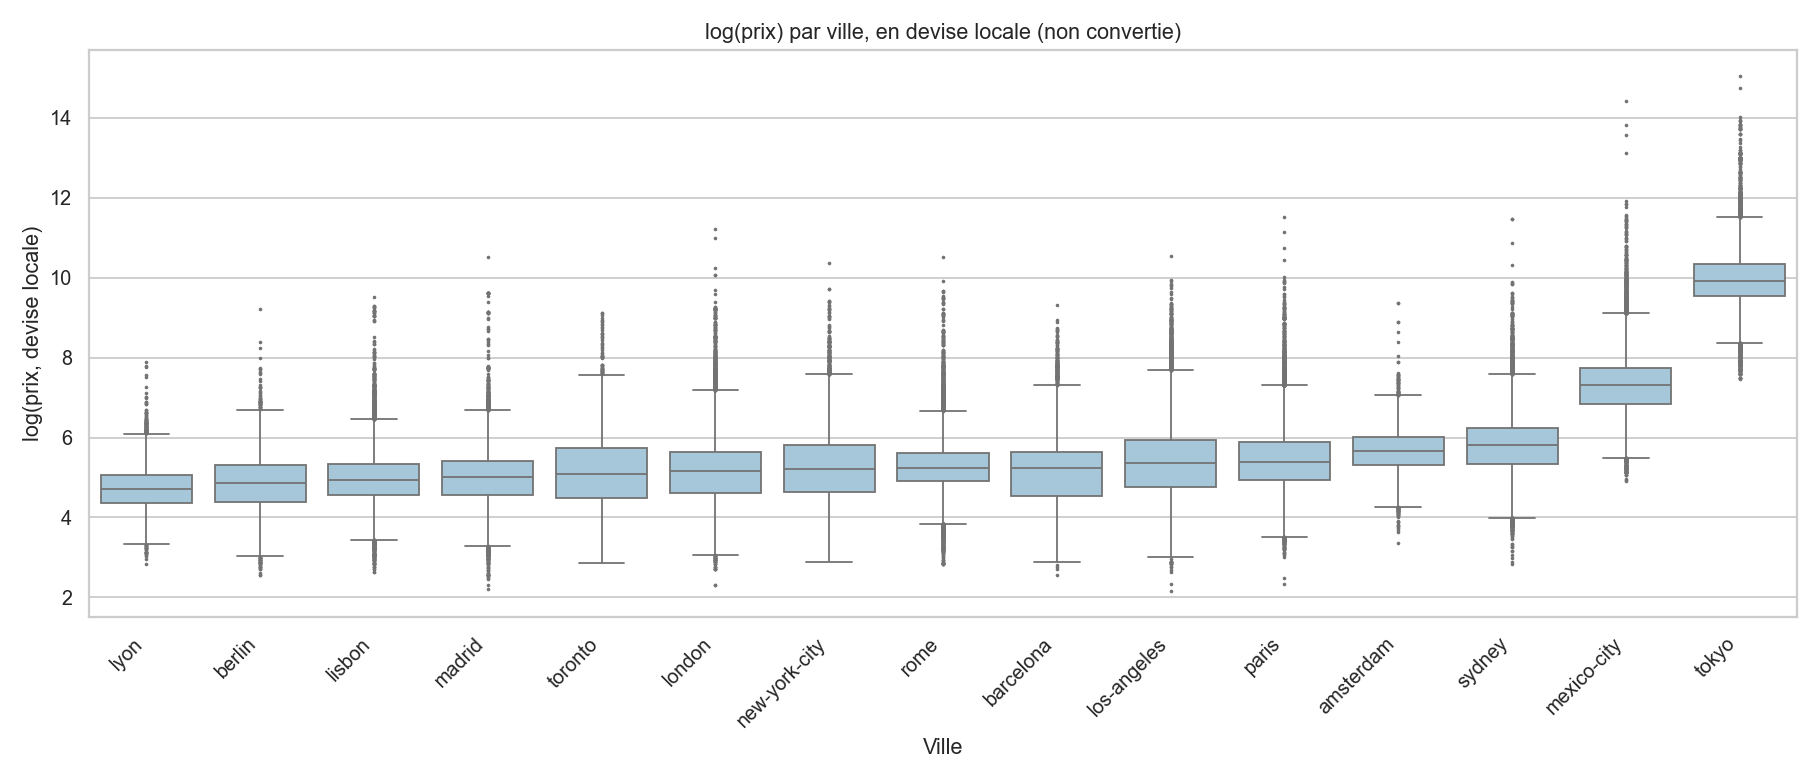

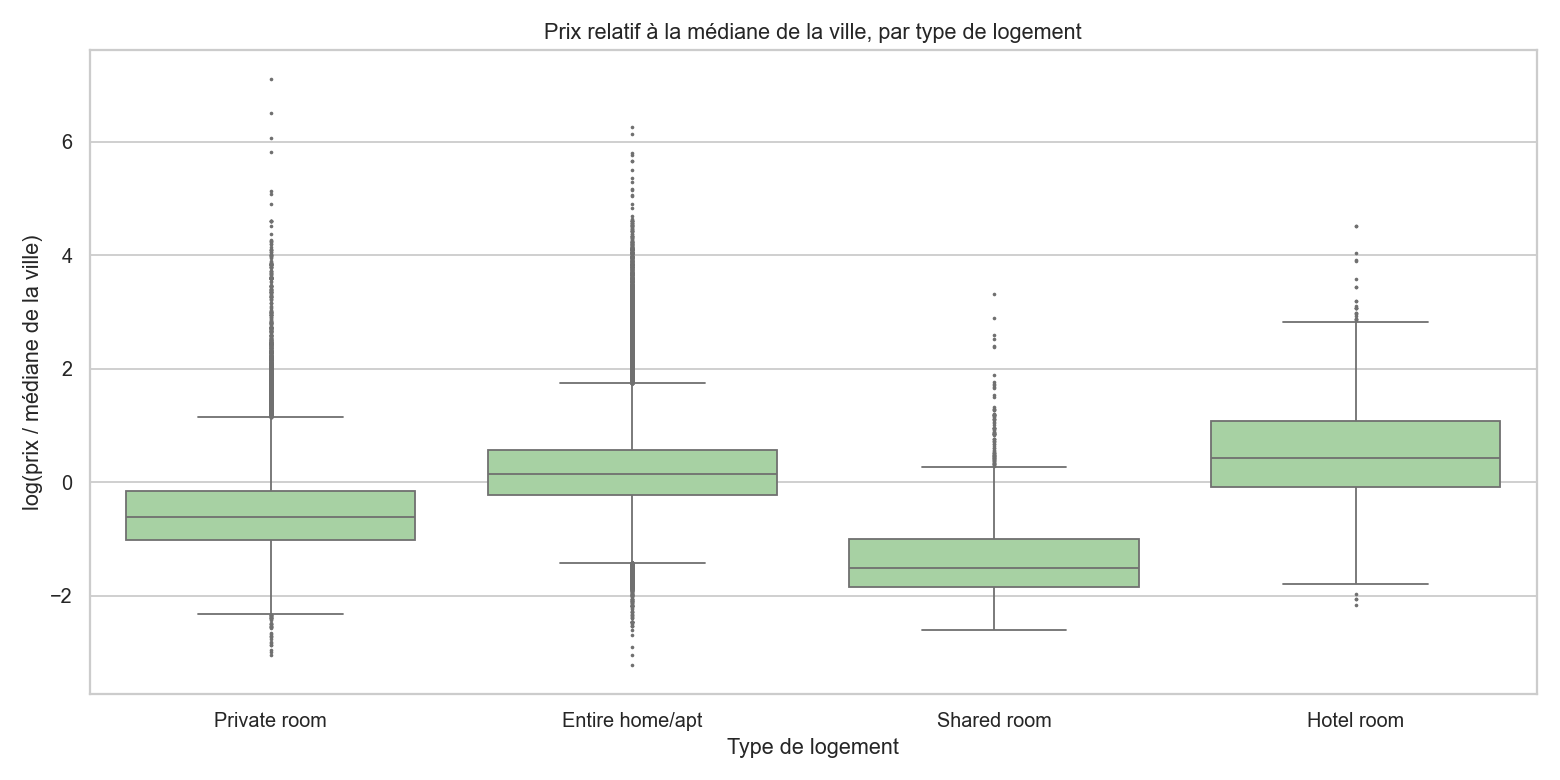

In [4]:
fig('02_price_paris_raw_vs_log')
fig('03_logprice_by_city_local_currency')
fig('04_rel_price_by_room_type')

## 3. Variables numériques
Pearson et Spearman : le prix dépend surtout de la capacité (accommodates, beds, bedrooms) ; peu de redondance forte.

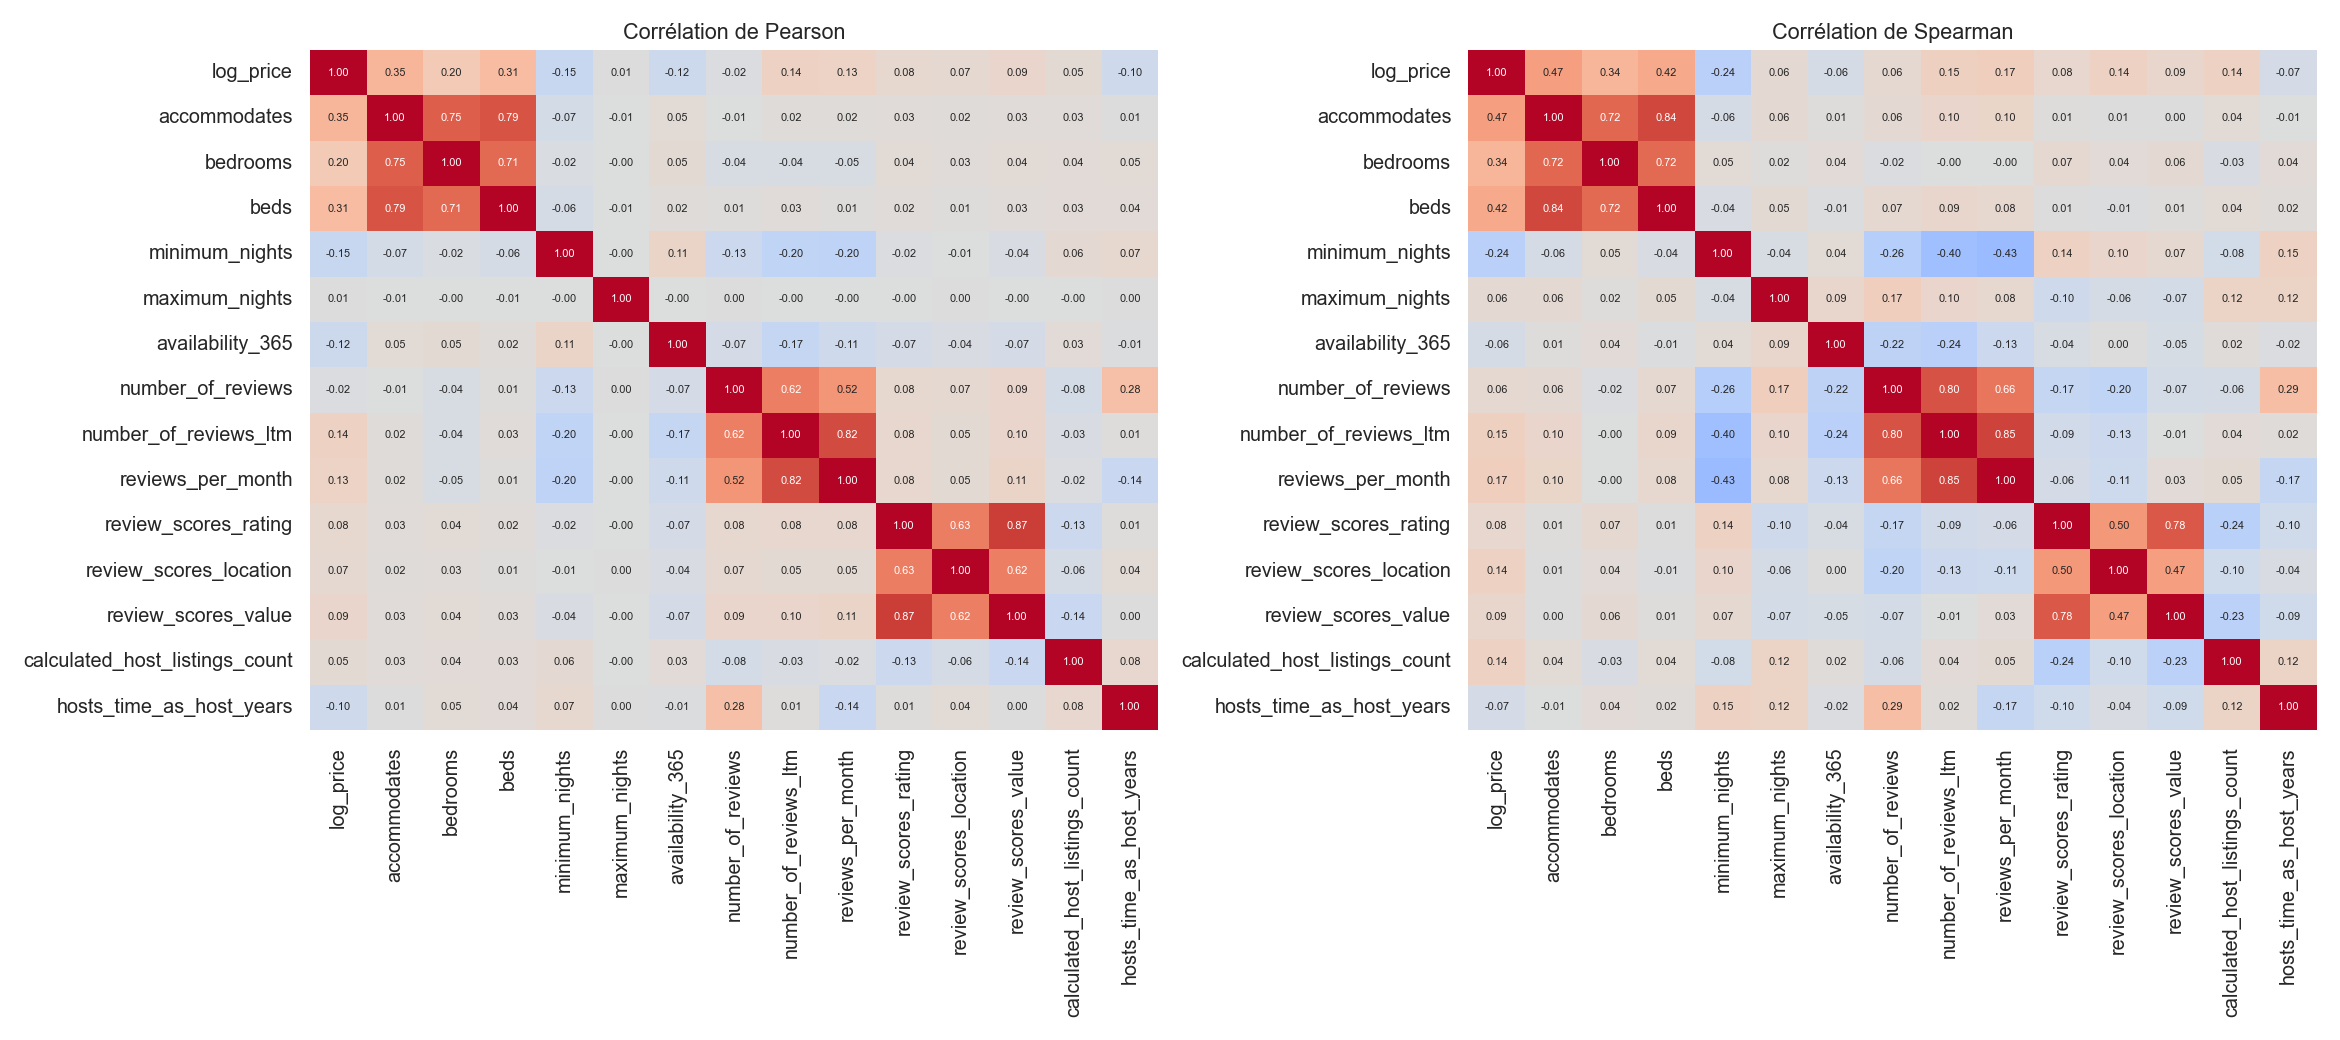

In [5]:
fig('05_correlations')

## 5. Géographie
Carte de Paris, prix médian par arrondissement, lien distance au centre / prix par ville.

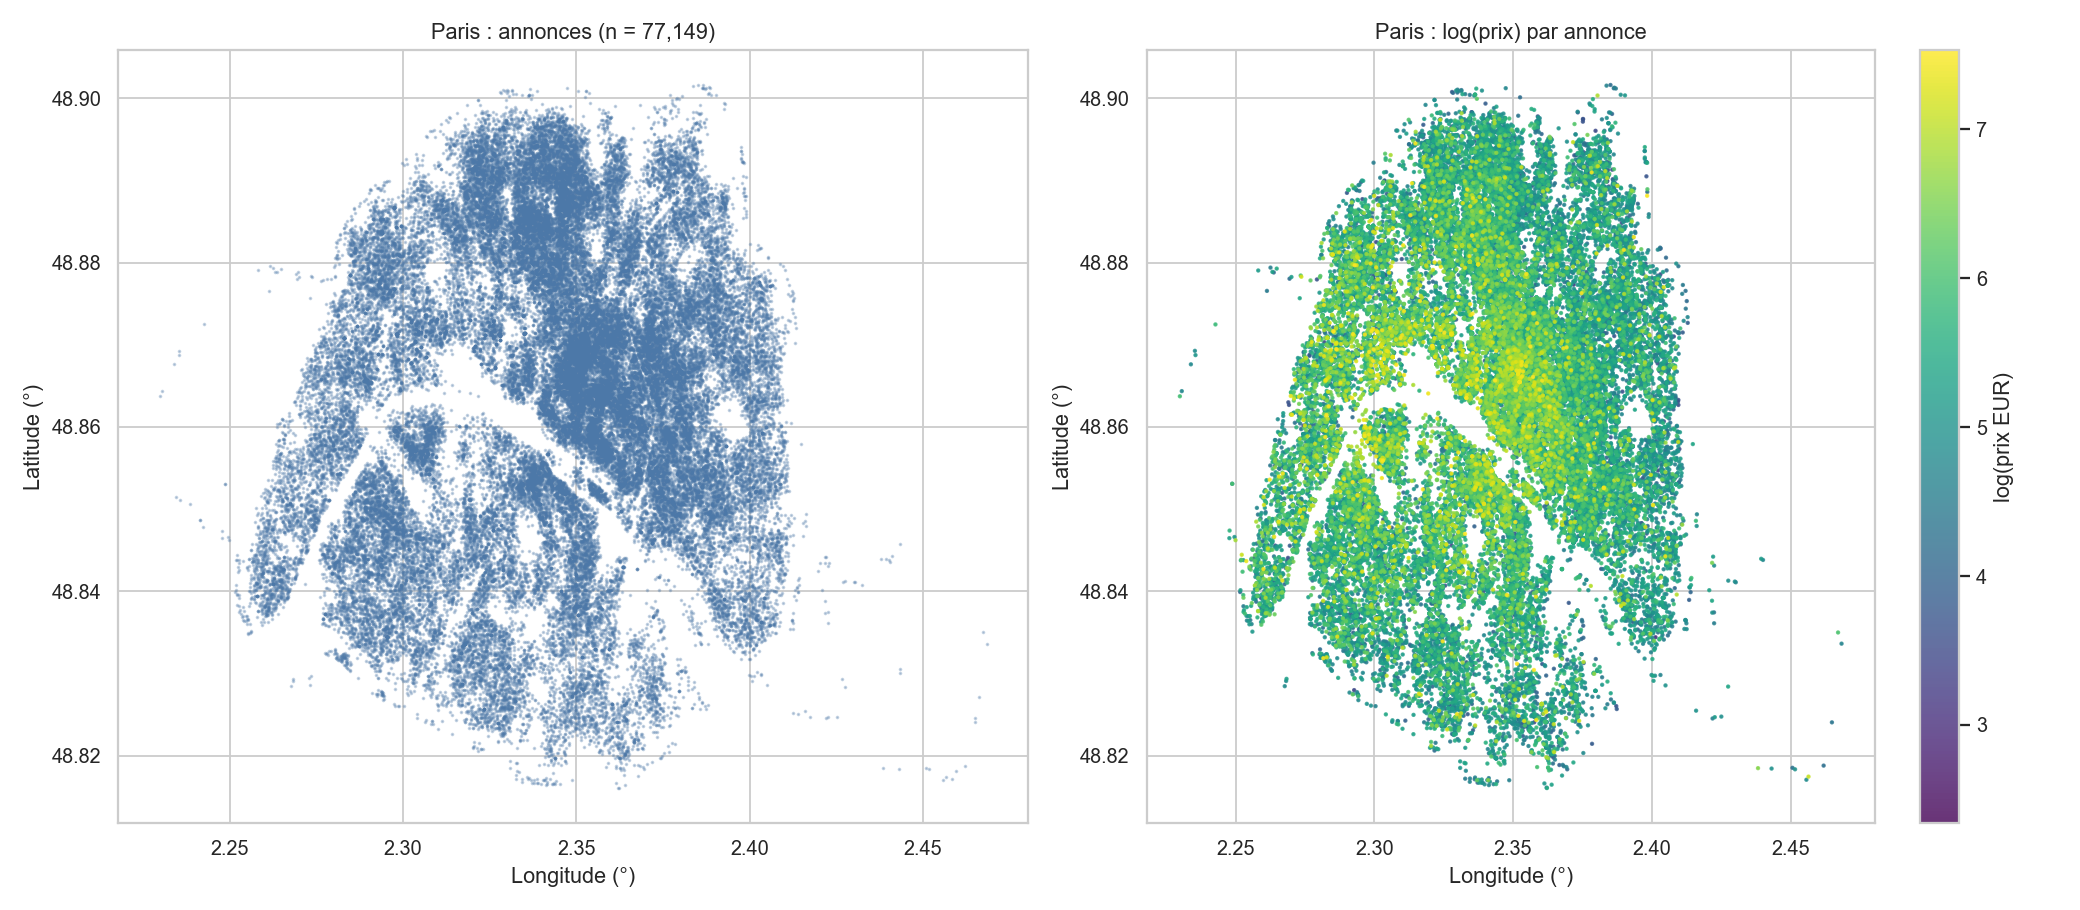

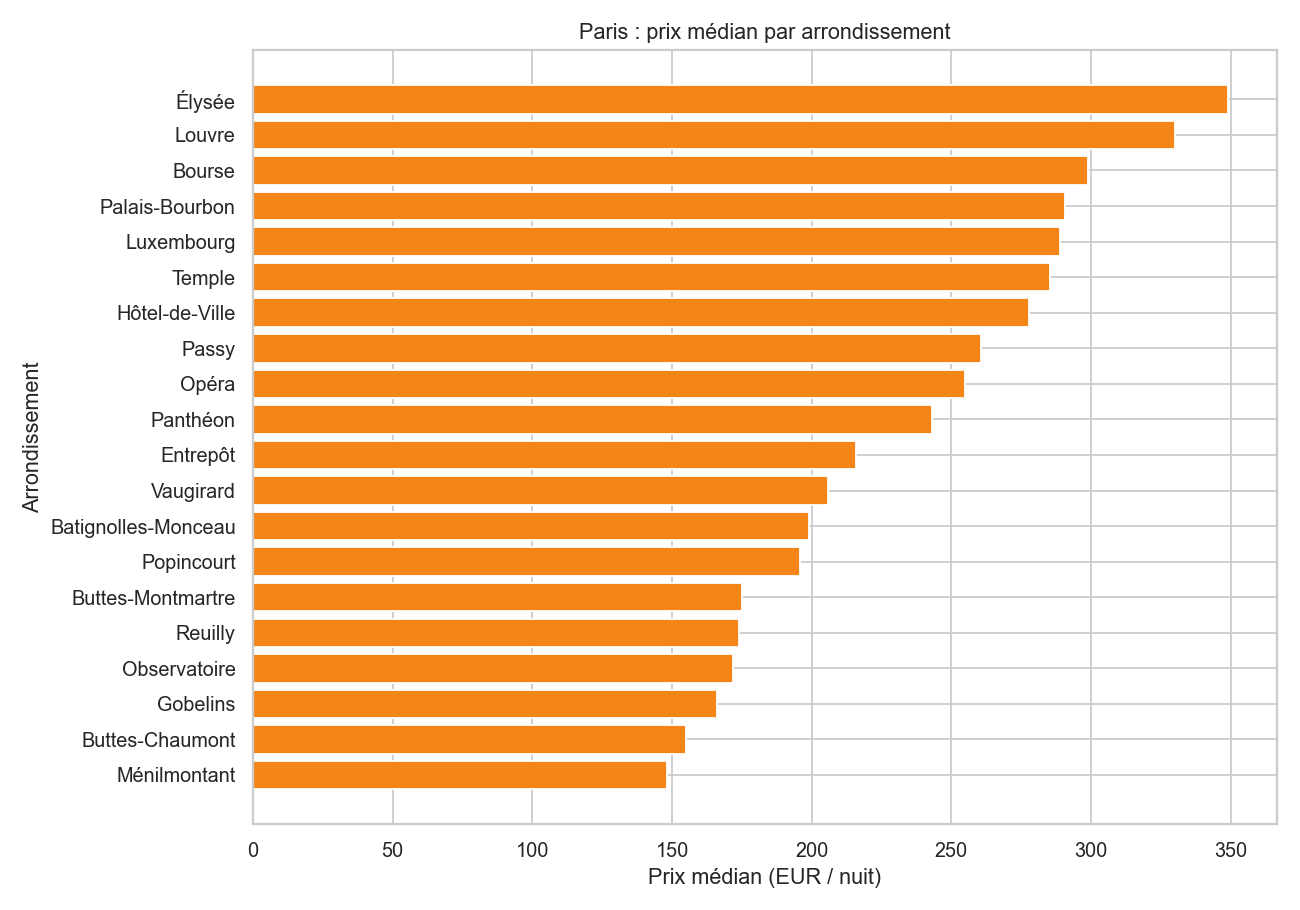

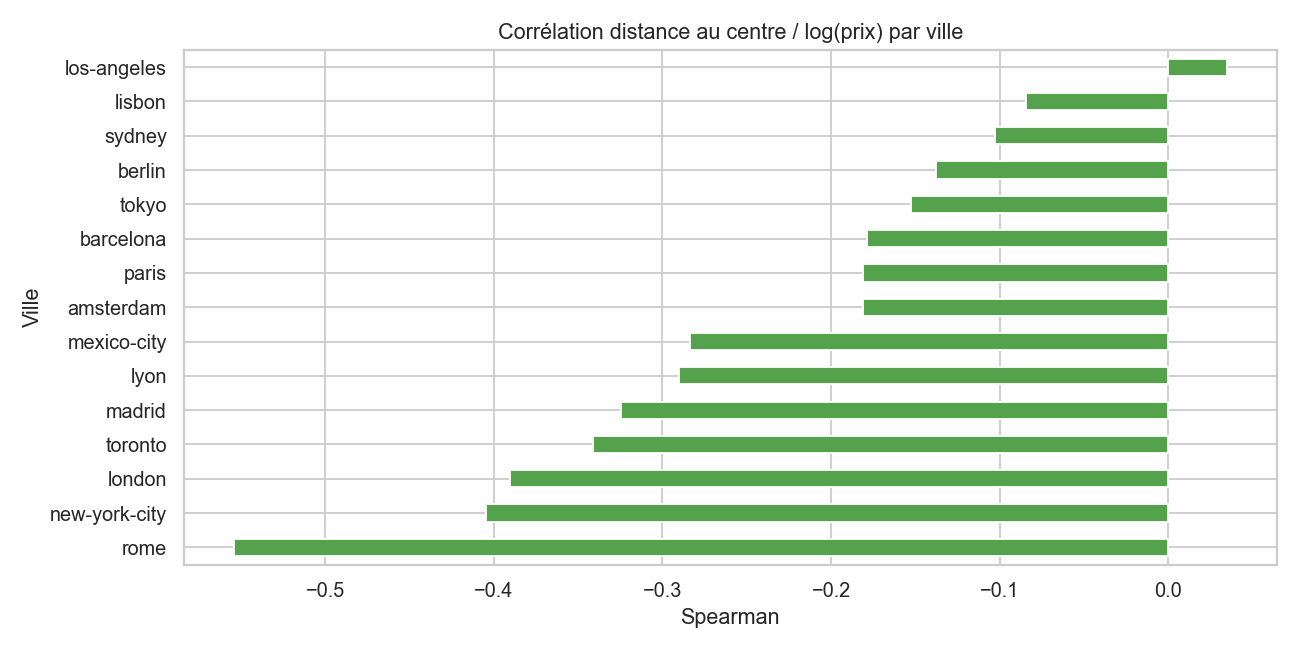

In [6]:
fig('06_map_paris')
fig('07_paris_median_price_by_neighbourhood')
fig('08_distance_price_corr_by_city')

## 6. Hôtes
Part de Superhosts et poids des hôtes multi-annonces par ville.

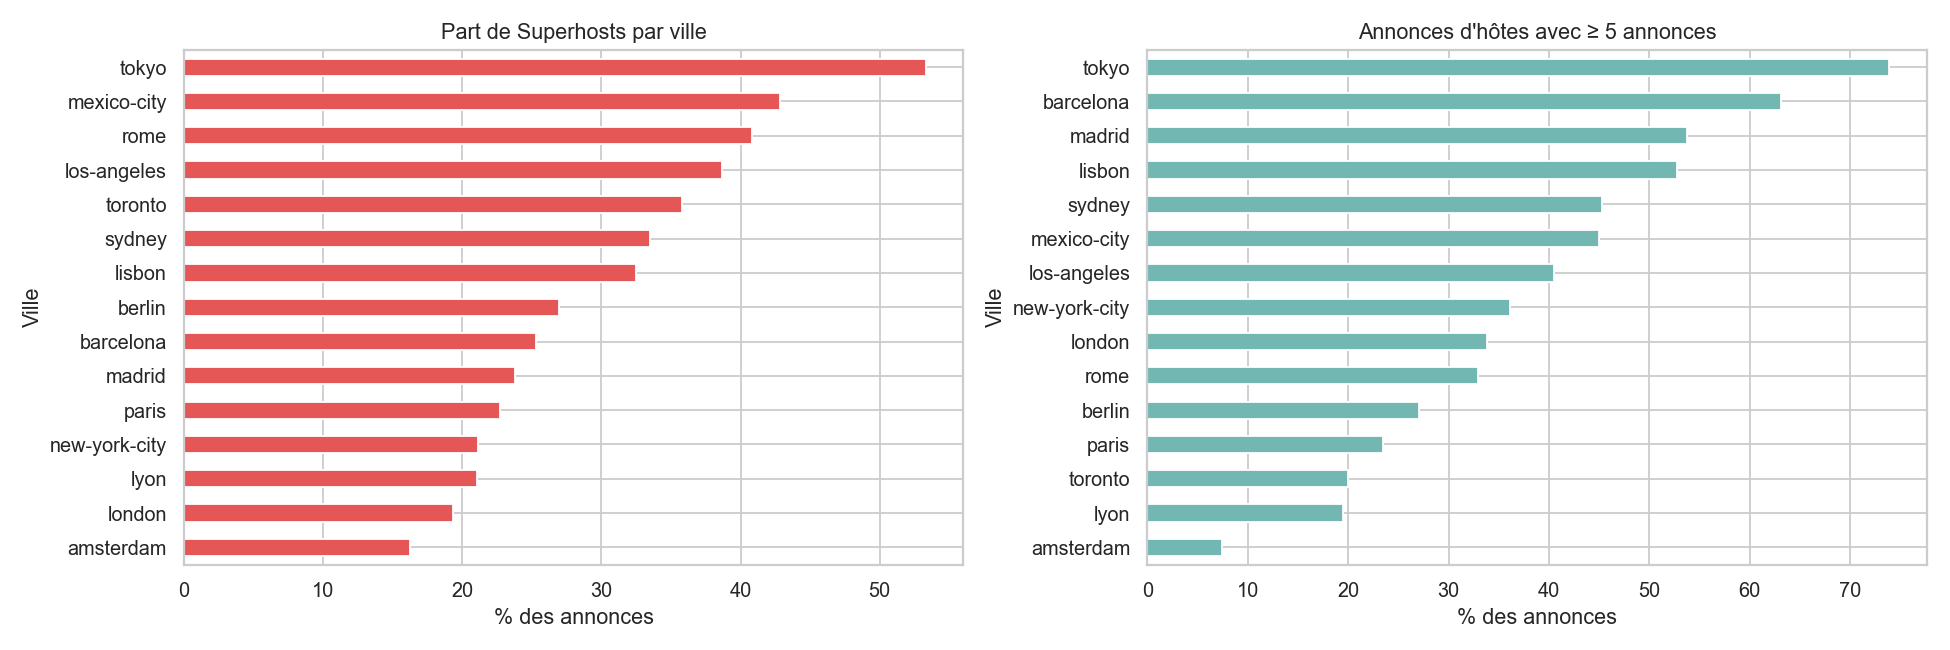

In [7]:
fig('09_hosts')

## 7. Avis
Forte positivité des notes ; 19 % d'annonces sans avis.

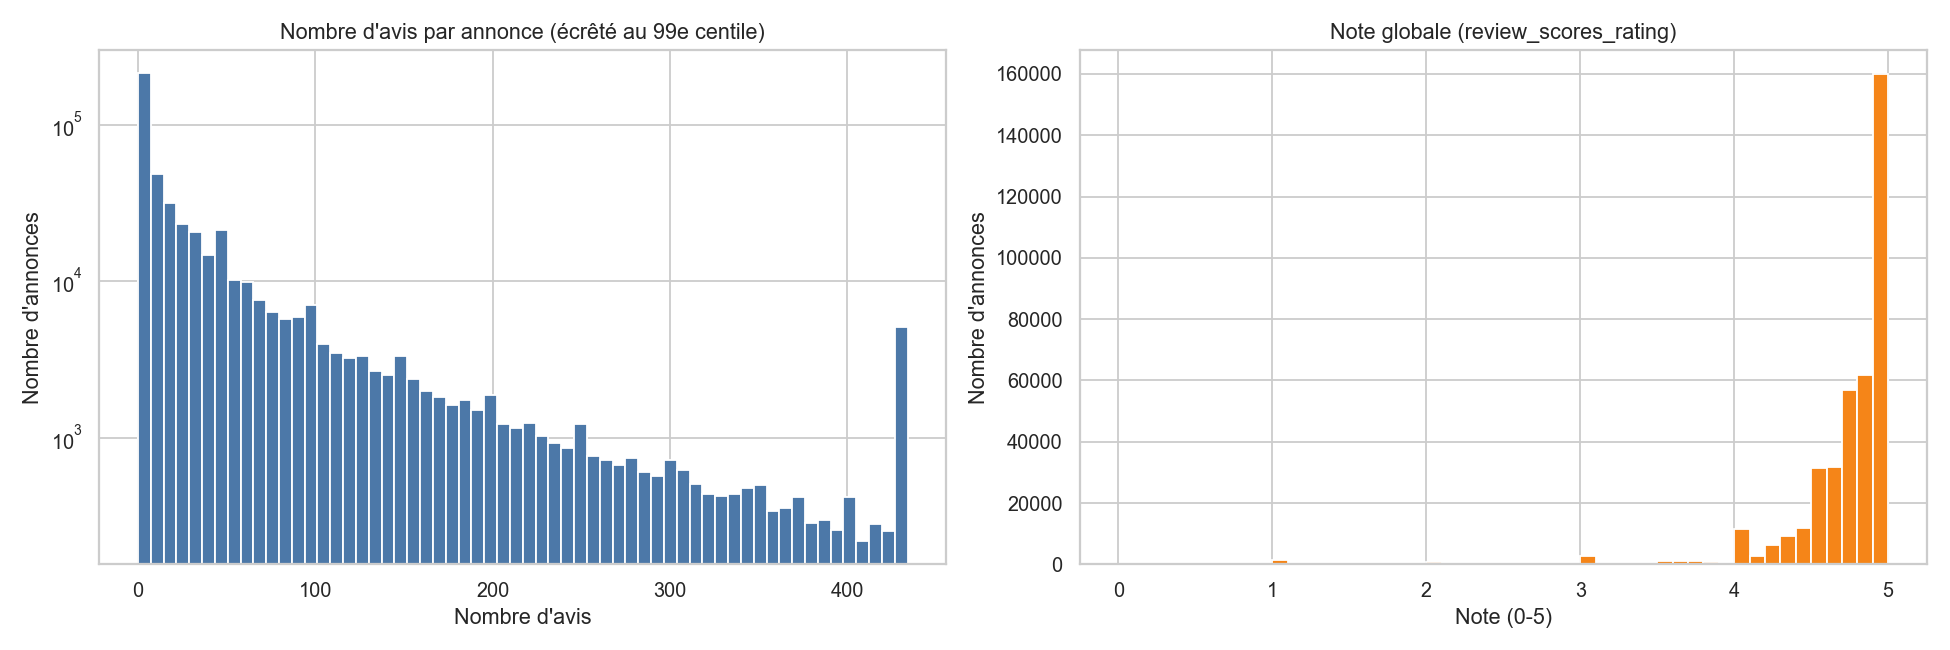

In [8]:
fig('10_reviews')

## 8. Annonces fantômes
Indisponibles toute l'année et sans avis récent.

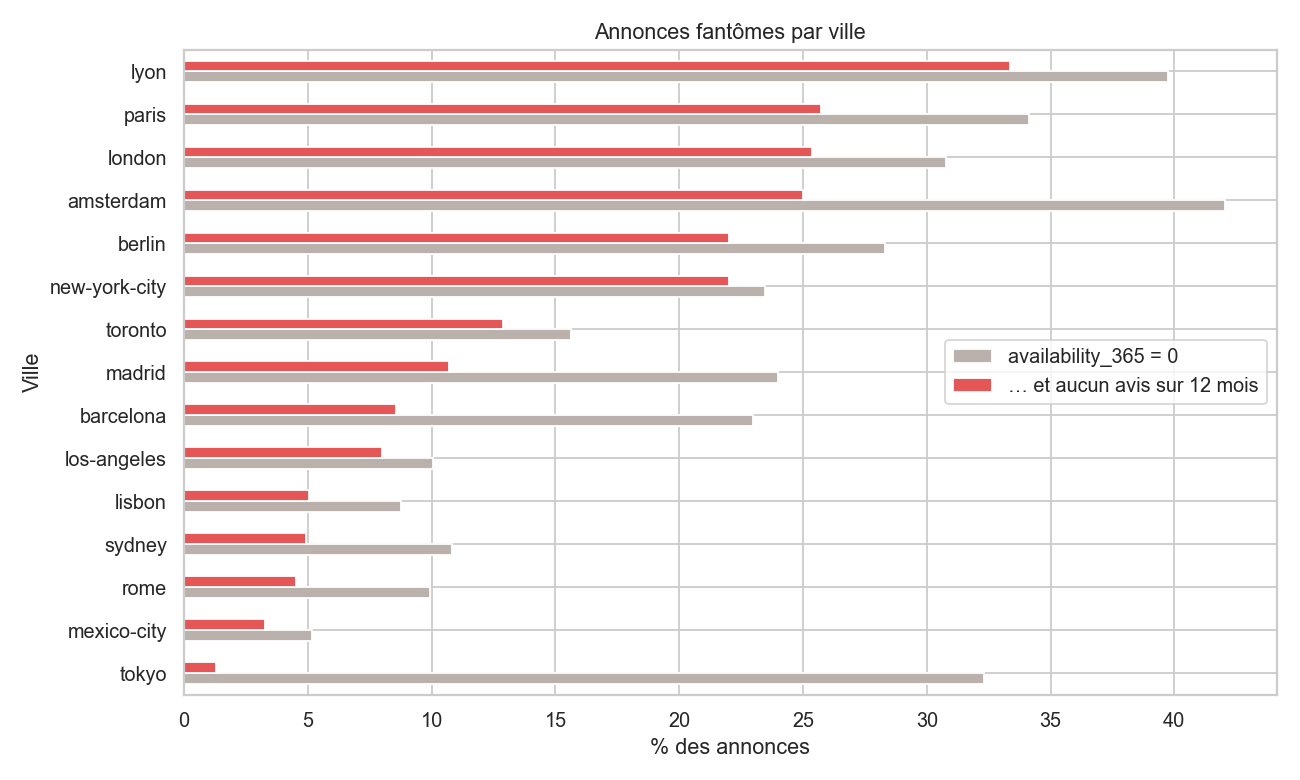

In [9]:
fig('11_ghost_listings')

## 4. Variables catégorielles
Cardinalité et modalités rares (property_type : 141 modalités ; quartiers : 1 294 couples ville-quartier).

In [10]:
pd.read_csv(ROOT / 'reports' / 'eda_categorical.csv')

,colonne,modalités,modalités <1 %,% annonces dans modalités <1 %
0,property_type,141,131,7.7
1,room_type,4,2,0.9
2,neighbourhood_cleansed,1287,1270,73.8
3,neighbourhood_group_cleansed,67,49,16.9
4,license,175337,175335,90.6
5,host_location,7107,7090,21.2
6,source,1,0,0.0


## Statistiques numériques

In [11]:
pd.read_csv(ROOT / 'reports' / 'eda_numeric_stats.csv', index_col=0)

,count,mean,std,min,25%,50%,75%,max,skew,miss_%
price,362593.0,3045.14,16828.58,8.57,126.39,226.29,509.00,3.465263e+06,57.46,25.26
accommodates,362593.0,3.70,2.38,1.00,2.00,3.00,4.00,1.600000e+01,1.87,0.00
bedrooms,362279.0,1.54,1.10,0.00,1.00,1.00,2.00,5.000000e+01,4.55,0.08
beds,353891.0,2.21,1.74,0.00,1.00,2.00,3.00,1.670000e+02,7.84,2.28
minimum_nights,346995.0,8.59,19.80,1.00,1.00,2.00,4.00,3.650000e+02,8.83,3.40
maximum_nights,346995.0,330037.33,26553261.49,1.00,180.00,365.00,1125.00,2.147484e+09,80.78,3.40
availability_365,362593.0,217.99,120.48,0.00,108.00,252.00,328.00,3.650000e+02,-0.44,0.00
number_of_reviews,362593.0,53.19,99.45,0.00,2.00,16.00,58.00,5.732000e+03,6.04,0.00
number_of_reviews_ltm,362593.0,14.04,23.18,0.00,0.00,5.00,20.00,1.525000e+03,8.16,0.00
reviews_per_month,302447.0,1.76,2.10,0.01,0.39,1.14,2.50,1.468700e+02,8.16,18.59


## 9. Pièges de fuite de données
- `estimated_revenue_l365d` = prix × occupation estimée : exclu de la régression.
- `price_quote_*` : le prix lui-même : exclu.
- Superhost : `review_scores_*`, `number_of_reviews_ltm` sont critères et conséquences du statut ; test avec/sans en phase 7.

In [12]:
pd.read_csv(ROOT / 'reports' / 'eda_leak_check.csv')

,colonne,spearman_vs_price
0,estimated_revenue_l365d,0.435
1,price_quote_price_per_night,1.000
2,price_quote_total_price,0.547
